# M06-5 (Optional) | Range Learning: Make scale/zero_point Trainable Parameters

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m06_qat_pipeline/05_learnable_fake_quant.ipynb)

So far, scale has been decided by the observer's statistics (a moving average of min/max), and training only changed the weights.
`LearnableFakeQuantize` makes scale and zero_point `nn.Parameter`s, so the loss gradient adjusts the quantization range directly. This is the LSQ approach.

We suggest reading the blog post "[Learning Zero-Point and Scale in Quantization Parameters](https://bobondemon.github.io/2022/12/04/Learning-Zero-Point-and-Scale-in-Quantization-Parameters/)" (in Chinese) first. It explains how LSQ/LSQ+ take gradients with respect to scale and zero_point, and what grad scaling is. Sections B and D are much easier after that.

- **A.** How to plug it into PT2E: swap the spec to `LearnableFakeQuantize`; the parameters are only created after one forward; scale must be clamped back to positive.
- **B.** Gradients: still STE with respect to x; the gradient with respect to scale is nonzero.
- **C.** The scale trajectory: observer version vs learnable version.
- **D.** The effect (int4, 3 seeds): observer, learnable, with grad scaling, and with a separate lr for qparams.

The whole notebook takes about 2 minutes to run.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m06_qat_pipeline")

In [2]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate, evaluate_loss, make_loader, trained_tiny_net
from common.graph_utils import observer_nodes, op_counts, sqnr
from common.models import example_inputs
from common.pt2e import (
    LearnableFakeQuantize,
    MovingAverageMinMaxObserver,
    convert_pt2e,
    enable_range_learning,
    export_module,
    prepare_qat_pt2e,
    quiet,
)
from common.qat import EPS, freeze_for_eval, make_schedule, qat_quantizer, train_qat
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#e6e5e1"

## A. Plugging It into PT2E

`qat_quantizer(weight_fq="learnable", act_fq="learnable")` (`common/qat.py`) only swaps the spec's `observer_or_fake_quant_ctr` for `LearnableFakeQuantize.with_args(observer=…)`; the conv + BN subgraph of `prepare_qat_pt2e` and convert's folding work as usual.

Training schedule: for the last 40% (from step 96) BN uses running stats, so that the graph in the last stretch of training is consistent with the convert graph (`make_schedule(bn_eval_at=96)`, a tool in this project's `common/qat.py` that calls `move_exported_model_to_eval` when the given step is reached); in addition, `enable_range_learning` is called at step 32: first let the observer collect the range for one epoch as the initial value, then start learning. `enable_range_learning` also turns the observers off, so from then on the range is decided by gradients only.

In [3]:
model = trained_tiny_net()
test_loader = make_loader(n=1024, seed=2, shuffle=False)
(x,) = next(calibration_batches(64, seed=9))
LEARN_AT = 32


def schedule(learn=True):
    bn = make_schedule(bn_eval_at=96)

    def on_step(step, m):
        bn(step, m)
        if learn and step == LEARN_AT:
            m.apply(enable_range_learning)

    return on_step


def prepare(**kw):
    return prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True), qat_quantizer(bits=4, **kw))


def n_qparams(gm):
    return sum(1 for n, _ in gm.named_parameters() if n.endswith((".scale", ".zero_point")))


prepared = prepare(weight_fq="learnable", act_fq="learnable")
before = n_qparams(prepared)
with torch.no_grad():
    prepared(*example_inputs())
after = n_qparams(prepared)
print("fake quant classes:", {type(m).__name__ for _, m in observer_nodes(prepared)})
print("batch_norm in the graph (QAT subgraph as usual):", op_counts(prepared).get("batch_norm", 0))
print(f"scale/zero_point parameters: {before} before forward, {after} after one forward")
assert before == 0 and after > 0

fake quant classes: {'LearnableFakeQuantize'}
batch_norm in the graph (QAT subgraph as usual): 4
scale/zero_point parameters: 0 before forward, 24 after one forward


scale/zero_point are created lazily: only on the first forward are they initialized into Parameters from the observer's statistics. The optimizer only remembers the parameters that exist when it is built, so **you must forward once before building the optimizer**. This is why `train_qat` forwards once at the start.

The second trap can only be caught with M06-3's check. By default `train_qat` clamps scale back to positive after every `opt.step()` (`clamp_scale=True`); below we compare turning it off and on:

In [4]:
rows, a = [], {}
for clamp in (False, True):
    p = train_qat(copy.deepcopy(prepared), epochs=5, on_step=schedule(), seed=1, clamp_scale=clamp)
    converted = convert_pt2e(freeze_for_eval(copy.deepcopy(p)))
    bad = [n.name for n, m in observer_nodes(p) if m.scale is not None and float(m.scale.min()) < EPS]
    with torch.no_grad():
        a[clamp] = sqnr(p(x), converted(x))
    rows.append(["yes" if clamp else "no", f"{a[clamp]:.1f}", ", ".join(bad) or "—"])
table(rows, ["Clamp scale back to positive every step", "fake quant graph vs convert graph (dB)", "Fake quants with scale ≤ 0"])

Clamp scale back to positive every step,fake quant graph vs convert graph (dB),Fake quants with scale ≤ 0
no,2.0,"activation_post_process_4, activation_post_process_10"
yes,inf,—


In [5]:
assert a[False] < 20 and a[True] == float("inf")

- Without the clamp, gradients push the scale of some channels negative. Forward still works, because $\mathrm{round}(w/s)\cdot s$ does not care about the sign of $s$. Whether it goes negative depends on the training process: with the same settings but BN not switched to eval, none of the 3 seeds tried here went negative, so clamping back to positive at every step is the safe practice.
- torchao 0.18's `LearnableFakeQuantize` clamps scale to eps only in `calculate_qparams()`, that is, when convert takes the qparams. The weights of those channels become almost all 0 in the convert graph, and the two graphs are left with single-digit dB at best.
- With the clamp back to positive at every step (`clamp_learnable_scales()` in `common/qat.py`), training and convert use the same scale, and we are back to inf.

## B. Gradients: STE with Respect to x, Nonzero with Respect to scale

A single int4 `LearnableFakeQuantize`, with the range initialized on [-1, 1] and then range learning turned on:

In [6]:
fq = LearnableFakeQuantize(observer=MovingAverageMinMaxObserver, quant_min=-8, quant_max=7, dtype=torch.int8,
                           qscheme=torch.per_tensor_affine, eps=EPS)
with torch.no_grad():
    fq(torch.linspace(-1, 1, 100))
fq.enable_range_learning()
xs = torch.tensor([-3.0, -0.5, 0.0, 0.3, 0.9, 1.5, 4.0], requires_grad=True)
fq(xs).sum().backward()
assert xs.grad is not None and fq.scale is not None and fq.scale.grad is not None
table([["dfq/dx", *(f"{float(g):.0f}" for g in xs.grad)]], ["x", *(f"{float(v):+.1f}" for v in xs)])

x,-3.0,-0.5,+0.0,+0.3,+0.9,+1.5,+4.0
dfq/dx,0,1,1,1,1,0,0


In [7]:
print(f"scale = {float(fq.scale):.4f}, d(sum fq)/d(scale) = {float(fq.scale.grad):.3f}")
assert float(fq.scale.grad) != 0

scale = 0.1333, d(sum fq)/d(scale) = 5.750


The gradient with respect to x is STE, the same as in M06-1. The gradient with respect to scale (LSQ): inside the range it is $\mathrm{round}(x/s) - x/s$, and outside the range it is $q_{min}$ or $q_{max}$.
Clamped values push scale larger, and the round error inside the range pushes scale smaller; which way it goes is decided by the loss, no longer by min/max.
`use_grad_scaling=True` divides the gradient of scale by $\sqrt{\text{numel} \times q_{max}}$ (the LSQ paper's suggestion); section D looks at its effect.

## C. The scale Trajectory

Record the scale of the input's fake quant (`activation_post_process_0`), once every 32 steps:

In [8]:
traj = {}
for name, kw, learn in (("observer", {}, False), ("learnable", dict(weight_fq="learnable", act_fq="learnable"), True)):
    t = []

    def log(step, m, t=t):
        if step % 32 == 0:
            t.append(float(m.get_submodule("activation_post_process_0").calculate_qparams()[0]))

    train_qat(prepare(**kw), epochs=5, on_step=schedule(learn), seed=1, log=log)
    traj[name] = t
STEPS = list(range(32, 161, 32))

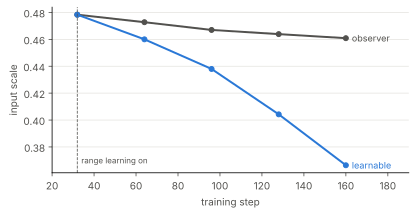

In [9]:
#| code-fold: true
#| code-summary: Plotting code
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for (name, t), color in zip(traj.items(), (MUTED, BLUE)):
    ax.plot(STEPS, t, color=color, lw=2, marker="o", ms=5)
    ax.annotate(name, (STEPS[-1], t[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=color, fontsize=9)
ax.axvline(LEARN_AT, color=MUTED, lw=0.8, ls="--")
ax.annotate("range learning on", (LEARN_AT, min(min(t) for t in traj.values())), xytext=(4, 0),
            textcoords="offset points", color=MUTED, fontsize=8, va="bottom")
ax.set_xlim(20, 190)
ax.set_xlabel("training step", color=MUTED)
ax.set_ylabel("input scale", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [10]:
assert traj["learnable"][-1] < traj["observer"][-1]

The observer version's scale only drifts slowly with the moving average; the learnable version is continuously pushed smaller by gradients from step 32 on: it shrinks the range to get a finer grid inside the range, at the cost of clamping more values.

## D. The Effect

int4, lr 1e-3, BN eval @96, 3 seeds per setting. Evaluation uses the fake quant graph after freeze (section A already confirmed it equals the convert graph):

In [11]:
CONFIGS = {
    "observer (range not learned)": ({}, {}),
    "learnable": (dict(weight_fq="learnable", act_fq="learnable"), {}),
    "learnable + grad scaling": (dict(weight_fq="learnable", act_fq="learnable", grad_scaling=True), {}),
    "learnable + grad scaling, qparams lr 1e-2": (dict(weight_fq="learnable", act_fq="learnable", grad_scaling=True),
                                                 dict(qparams_lr=1e-2)),
    "learnable, qparams lr 1e-2 (no grad scaling)": (dict(weight_fq="learnable", act_fq="learnable"), dict(qparams_lr=1e-2)),
}
d = {}
for name, (qkw, tkw) in CONFIGS.items():
    base, losses, accs = prepare(**qkw), [], []
    for seed in (1, 2, 3):
        p = freeze_for_eval(train_qat(copy.deepcopy(base), epochs=5, on_step=schedule(name != "observer (range not learned)"),
                                      seed=seed, **tkw))
        losses.append(evaluate_loss(p, test_loader))
        accs.append(evaluate(p, test_loader))
    d[name] = (losses, sum(accs) / 3)
table([[name, f"{sum(v) / 3:.3f}", f"{min(v):.3f} ~ {max(v):.3f}", f"{acc:.3f}"] for name, (v, acc) in d.items()],
      ["Setting", "Mean test loss", "min ~ max", "Mean accuracy"])

Setting,Mean test loss,min ~ max,Mean accuracy
observer (range not learned),0.831,0.729 ~ 1.027,0.733
learnable,0.779,0.704 ~ 0.818,0.694
learnable + grad scaling,0.783,0.693 ~ 0.881,0.731
"learnable + grad scaling, qparams lr 1e-2",0.867,0.752 ~ 1.037,0.704
"learnable, qparams lr 1e-2 (no grad scaling)",1.399,1.386 ~ 1.411,0.252


In [12]:
obs, learn = d["observer (range not learned)"][0], d["learnable"][0]
gs = d["learnable + grad scaling"][0]
# Which of the first four settings is best depends on the platform and the seeds (see the notes below); only divergence is stable.
assert d["learnable, qparams lr 1e-2 (no grad scaling)"][1] < 0.3  # diverges: accuracy near random guessing over 4 classes

- **Switch to learnable (nothing else changed)**: the mean test loss is lower than the observer version on both platforms (macOS arm64: 0.757 vs 0.883; Linux x86, shown here: 0.779 vs 0.831), and the range across seeds is the narrowest or close to it. On macOS arm64 all 3 seeds beat the observer version; on Linux x86 the ranges overlap (learnable 0.704 ~ 0.818, observer 0.729 ~ 1.027), so "wins on every seed" does not hold there. The training is not bit-reproducible across platforms even from the same starting weights, which is why only the mean is a fair comparison.
- **Add grad scaling**: the gradient of scale becomes smaller and it moves slowly. On macOS arm64 this made the mean worse than plain learnable and the range wider (0.840, 0.753 ~ 0.941); on Linux x86 it is about the same as plain learnable (0.783) with a wider range. Raising the lr of qparams on top of it did not help on either platform (0.806 on macOS, 0.867 on Linux).
- **No grad scaling but qparams lr 1e-2**: it diverges outright, and accuracy drops to random guessing over 4 classes (on both platforms). The lr of scale and grad scaling are tied together and can only be tuned together.
- This is the result of a single model and 3 seeds. The settings that differ by about 0.05 in mean loss swap places between the two platforms, so differences of that size are within the noise; whether "better without grad scaling" (or the opposite) holds on other models is not verified here.

## Summary

- Plugging it into PT2E only needs a spec swap; but the optimizer must be built after one forward, and scale must be clamped back to positive at every step, otherwise training graph ≠ convert graph.
- Range learning also hands the range to the loss to decide; the cost is an extra set of hyperparameters (grad scaling, the lr of qparams), and a wrong choice diverges. On this small model it beat the observer version on the mean on both platforms, but not on every seed on every platform.